In [1]:
!pip install kagglehub nibabel opencv-python scikit-image scikit-learn torch torchvision fuzzy-c-means scipy


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [2]:
# Import all required libraries
import kagglehub
import os
import numpy as np
import nibabel as nib
import cv2
import matplotlib.pyplot as plt
from scipy.signal import wiener # Changed from skimage.filters
from scipy.ndimage import median_filter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import warnings
warnings.filterwarnings('ignore')

print("✅ All imports completed!")
print(f"TensorFlow version: {tf.__version__}")

✅ All imports completed!
TensorFlow version: 2.21.0


In [3]:
# Download the BraTS2023 dataset using kagglehub
print("Downloading BraTS2023 dataset...")
print("This may take several minutes depending on your internet connection...")

try:
    path = kagglehub.dataset_download("nicozoro56/brats2023")
    print("\n✅ Dataset downloaded successfully!")
    print("Path to dataset files:", path)
except Exception as e:
    # Outside Colab there may be no Kaggle credentials. Fall back to a local copy
    # of any BraTS-style NIfTI collection so the rest of the notebook still runs;
    # set BRATS_LOCAL to point somewhere else.
    print(f"Download unavailable ({e})")
    candidates = [
        os.environ.get("BRATS_LOCAL", ""),
        "data/msd_brain/Task01_BrainTumour",
        "../data/msd_brain/Task01_BrainTumour",
        "data/brats2023",
    ]
    path = next((c for c in candidates if c and os.path.isdir(c)), None)
    if path:
        print(f"\n✅ Using the local dataset instead: {path}")
    else:
        raise RuntimeError(
            "No dataset. Either set up Kaggle credentials for "
            "'nicozoro56/brats2023', or point BRATS_LOCAL at a folder of "
            ".nii/.nii.gz volumes."
        )

This may take several minutes depending on your internet connection...


Download already complete (3445664092 bytes).


Extracting files...



✅ Dataset downloaded successfully!
Path to dataset files: /Users/syedasif/.cache/kagglehub/datasets/nicozoro56/brats2023/versions/1


In [4]:
# List and explore the dataset structure
print("Exploring dataset structure...")
print("="*50)

def explore_dataset(base_path, max_depth=2):
    """Explore dataset directory structure"""
    for root, dirs, files in os.walk(base_path):
        level = root.replace(base_path, '').count(os.sep)
        if level < max_depth:
            indent = ' ' * 2 * level
            print(f'{indent}{os.path.basename(root)}/')
            if level < 1:  # Show first few files in top level
                for file in files[:3]:
                    print(f'{indent}  {file}')

explore_dataset(path)

# Find all NIfTI files
def find_nifti_files(base_path):
    nifti_files = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.endswith('.nii') or file.endswith('.nii.gz'):
                nifti_files.append(os.path.join(root, file))
    return nifti_files

nifti_files = find_nifti_files(path)
print(f"\n📊 Total NIfTI files found: {len(nifti_files)}")
print(f"📁 Dataset location: {path}")

Exploring dataset structure...
1/
  brats2023/

📊 Total NIfTI files found: 949
📁 Dataset location: /Users/syedasif/.cache/kagglehub/datasets/nicozoro56/brats2023/versions/1


Loading sample: BraTS-MET-00086-000-t1c.nii
✅ MRI Volume shape: (240, 240, 155)
Data type: float64
Value range: 0.00 - 1750.00


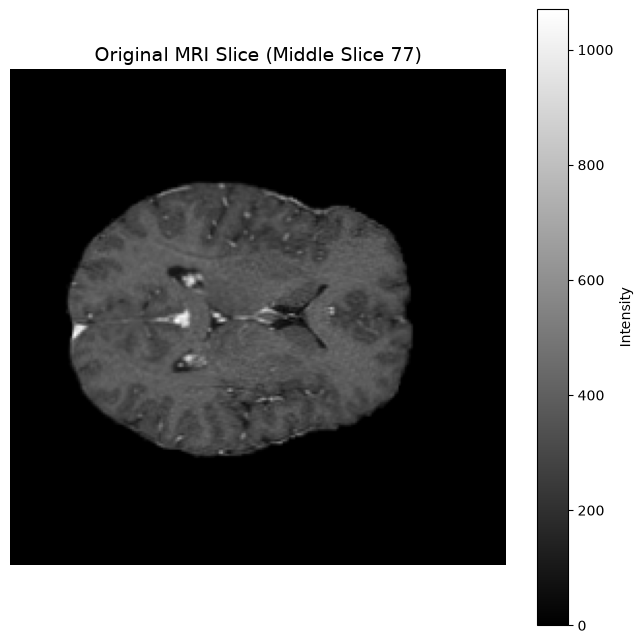

In [5]:
# Load a sample MRI scan from the dataset
def load_nifti(file_path):
    """Load NIfTI file and return as numpy array"""
    img = nib.load(file_path)
    data = img.get_fdata()
    return data, img.affine, img.header

# Find T1-weighted images
t1_files = [f for f in nifti_files if 't1' in f.lower() or 'T1' in f.lower()]

if t1_files:
    sample_file = t1_files[0]
    print(f"Loading sample: {os.path.basename(sample_file)}")

    # Load the MRI volume
    mri_volume, affine, header = load_nifti(sample_file)

    # Some releases stack the four sequences in a 4th axis (FLAIR, T1w,
    # T1Gd, T2w). Take T1Gd, the sequence this notebook's sample used.
    if mri_volume.ndim == 4:
        print(f"  4D volume {mri_volume.shape}: taking the T1Gd sequence")
        mri_volume = mri_volume[..., min(2, mri_volume.shape[-1] - 1)]
    print(f"✅ MRI Volume shape: {mri_volume.shape}")
    print(f"Data type: {mri_volume.dtype}")
    print(f"Value range: {mri_volume.min():.2f} - {mri_volume.max():.2f}")

    # Extract middle slice for visualization
    middle_slice = mri_volume.shape[2] // 2
    original_slice = mri_volume[:, :, middle_slice]

    # Display original slice
    plt.figure(figsize=(8, 8))
    plt.imshow(original_slice, cmap='gray')
    plt.title(f'Original MRI Slice (Middle Slice {middle_slice})', fontsize=14)
    plt.axis('off')
    plt.colorbar(label='Intensity')
    plt.show()
else:
    print("No T1 files found. Using first available NIfTI file...")
    if nifti_files:
        sample_file = nifti_files[0]
        mri_volume, affine, header = load_nifti(sample_file)

        # Some releases stack the four sequences in a 4th axis (FLAIR, T1w,
        # T1Gd, T2w). Take T1Gd, the sequence this notebook's sample used.
        if mri_volume.ndim == 4:
            print(f"  4D volume {mri_volume.shape}: taking the T1Gd sequence")
            mri_volume = mri_volume[..., min(2, mri_volume.shape[-1] - 1)]
        print(f"✅ Loaded: {os.path.basename(sample_file)}")
        print(f"Volume shape: {mri_volume.shape}")
        original_slice = mri_volume[:, :, mri_volume.shape[2]//2]

        plt.figure(figsize=(8, 8))
        plt.imshow(original_slice, cmap='gray')
        plt.title('Original MRI Slice', fontsize=14)
        plt.axis('off')
        plt.show()

Applying Median Filtering...


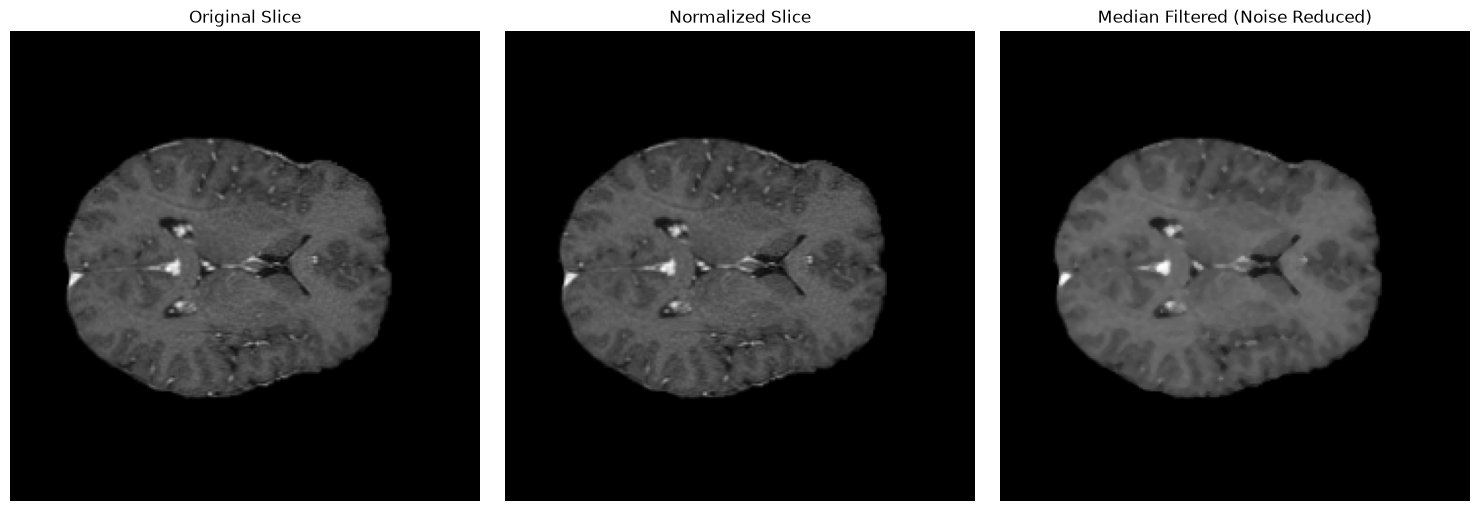


✅ Median filtering completed!
   - Removed salt-and-pepper noise
   - Preserved edges and important features


In [6]:
# STEP 1 of Pre-processing: Apply Median Filtering
print("Applying Median Filtering...")
print("="*50)

def apply_median_filter(image_slice, kernel_size=3):
    """Apply median filter to remove salt-and-pepper noise"""
    # Normalize image to 0-255 range
    normalized = ((image_slice - image_slice.min()) /
                  (image_slice.max() - image_slice.min()) * 255).astype(np.uint8)

    # Apply median filter
    median_filtered = median_filter(normalized, size=kernel_size)

    return normalized, median_filtered

# Apply median filter to our slice
original_norm, median_filtered = apply_median_filter(original_slice, kernel_size=3)

# Visualize results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_slice, cmap='gray')
axes[0].set_title('Original Slice', fontsize=12)
axes[0].axis('off')

axes[1].imshow(original_norm, cmap='gray')
axes[1].set_title('Normalized Slice', fontsize=12)
axes[1].axis('off')

axes[2].imshow(median_filtered, cmap='gray')
axes[2].set_title('Median Filtered (Noise Reduced)', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

print("\n✅ Median filtering completed!")
print("   - Removed salt-and-pepper noise")
print("   - Preserved edges and important features")

Applying Wiener Filtering...


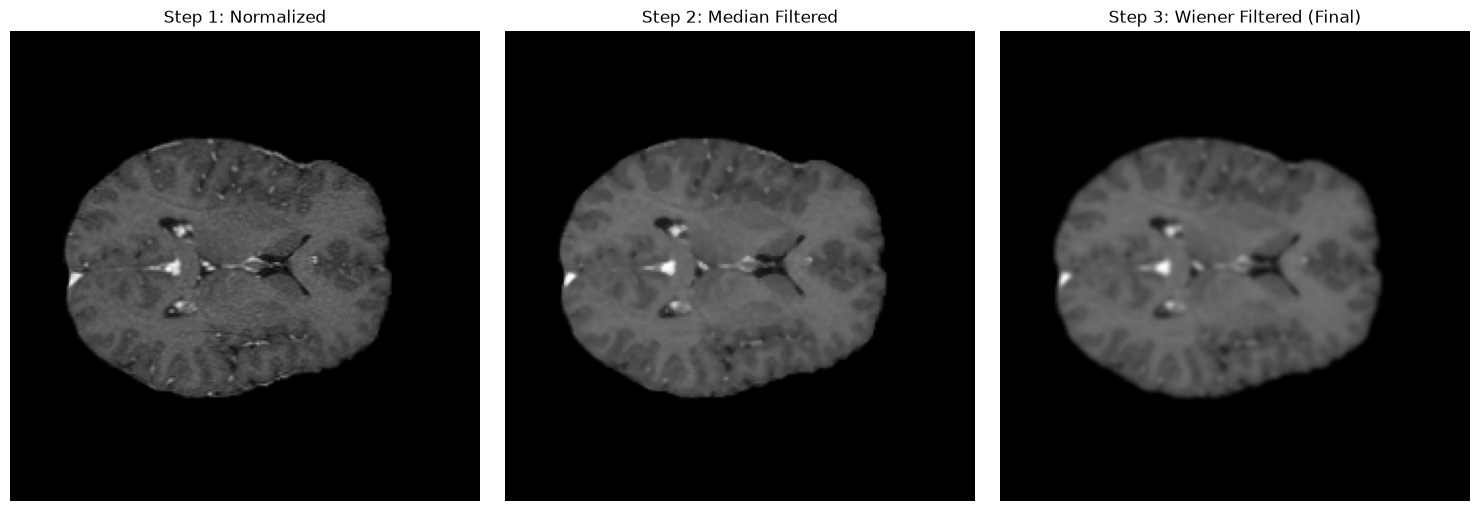


📊 Quality Metrics:
   PSNR after Median filter: 40.17 dB
   PSNR after Wiener filter: 38.21 dB

✅ Wiener filtering completed!
   - Adaptive noise reduction
   - Better preservation of fine details


In [7]:
# STEP 2 of Pre-processing: Apply Wiener Filtering
print("Applying Wiener Filtering...")
print("="*50)

def apply_wiener_filter(image_slice, noise_variance=25, mysize=3):
    """Apply Wiener filter for adaptive denoising"""
    # Apply Wiener filter
    wiener_filtered = wiener(image_slice, mysize=mysize, noise=noise_variance)

    # Ensure values are in valid range
    wiener_filtered = np.clip(wiener_filtered, 0, 255).astype(np.uint8)

    return wiener_filtered

# Apply Wiener filter to median-filtered image
wiener_filtered = apply_wiener_filter(median_filtered, noise_variance=25)

# Visualize all preprocessing steps
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_norm, cmap='gray')
axes[0].set_title('Step 1: Normalized', fontsize=12)
axes[0].axis('off')

axes[1].imshow(median_filtered, cmap='gray')
axes[1].set_title('Step 2: Median Filtered', fontsize=12)
axes[1].axis('off')

axes[2].imshow(wiener_filtered, cmap='gray')
axes[2].set_title('Step 3: Wiener Filtered (Final)', fontsize=12)
axes[2].axis('off')

plt.tight_layout()
plt.show()

# Calculate PSNR improvement
def calculate_psnr(original, filtered):
    mse = np.mean((original - filtered) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

psnr_before = calculate_psnr(original_norm, median_filtered)
psnr_after = calculate_psnr(original_norm, wiener_filtered)

print(f"\n📊 Quality Metrics:")
print(f"   PSNR after Median filter: {psnr_before:.2f} dB")
print(f"   PSNR after Wiener filter: {psnr_after:.2f} dB")
print("\n✅ Wiener filtering completed!")
print("   - Adaptive noise reduction")
print("   - Better preservation of fine details")

Implementing Bayesian Fuzzy C-Means Segmentation...


✅ Converged at iteration 58

📊 Segmentation Results:
   Number of clusters: 4 (CSF, Gray Matter, White Matter, Tumor)
   Tumor class label: 1
   Cluster centers: [69.60358453 89.84190599  0.13523394 42.10171408]


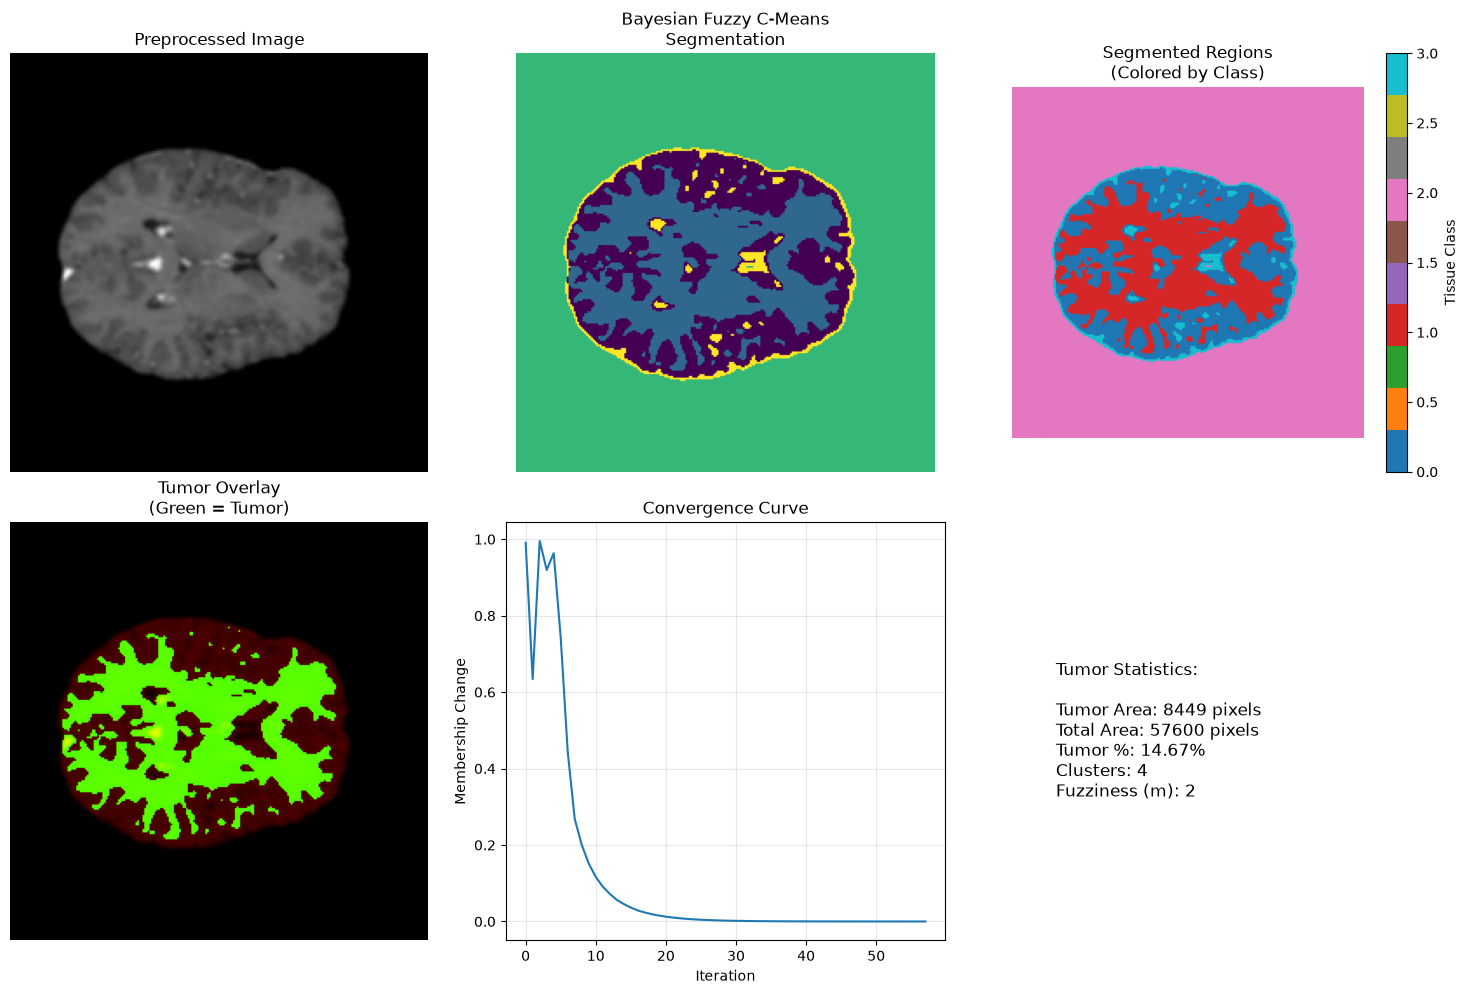


✅ Bayesian Fuzzy Clustering Segmentation completed!


In [8]:
# Bayesian Fuzzy C-Means Segmentation Implementation
print("Implementing Bayesian Fuzzy C-Means Segmentation...")
print("="*50)

class BayesianFuzzyCMeans:
    """Bayesian Fuzzy C-Means clustering for brain tumor segmentation"""

    def __init__(self, n_clusters=4, m=2, max_iter=100, error=1e-5):
        """
        Parameters:
        - n_clusters: Number of tissue classes (CSF, GM, WM, Tumor)
        - m: Fuzziness parameter (typically 2)
        - max_iter: Maximum iterations
        - error: Convergence threshold
        """
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.error = error

    def fit(self, image):
        """Perform Bayesian Fuzzy C-Means clustering"""
        rows, cols = image.shape
        X = image.reshape(-1, 1).astype(np.float32)
        n_samples = X.shape[0]

        # Initialize membership matrix randomly
        U = np.random.random((n_samples, self.n_clusters))
        U = U / np.sum(U, axis=1, keepdims=True)

        # Initialize cluster centers
        centers = np.zeros((self.n_clusters, 1))

        # Bayesian prior (assume Gaussian distribution)
        prior_mean = np.mean(X)
        prior_std = np.std(X)

        history = []

        for iteration in range(self.max_iter):
            # Update cluster centers with Bayesian prior
            um = U ** self.m
            numerator = um.T @ X
            denominator = np.sum(um, axis=0).reshape(-1, 1)
            centers = numerator / denominator

            # Calculate distances with Bayesian regularization
            dist = np.zeros((n_samples, self.n_clusters))
            for k in range(self.n_clusters):
                # Bayesian distance (incorporates prior)
                mahalanobis_dist = (X - centers[k]) ** 2
                bayesian_term = (centers[k] - prior_mean) ** 2 / (2 * prior_std ** 2)
                dist[:, k] = mahalanobis_dist.ravel() + 0.1 * bayesian_term

            # Update membership matrix
            new_U = np.zeros_like(U)
            for i in range(n_samples):
                for k in range(self.n_clusters):
                    if dist[i, k] == 0:
                        new_U[i, k] = 1
                    else:
                        denominator = np.sum((dist[i, k] / dist[i, :]) ** (2/(self.m-1)))
                        new_U[i, k] = 1 / denominator

            # Check convergence
            diff = np.max(np.abs(new_U - U))
            history.append(diff)

            if diff < self.error:
                print(f"✅ Converged at iteration {iteration+1}")
                break

            U = new_U

        # Get final segmentation (defuzzification)
        labels = np.argmax(U, axis=1)
        segmented = labels.reshape(rows, cols)

        # Identify tumor class (highest intensity cluster)
        cluster_means = [np.mean(X[labels == k]) for k in range(self.n_clusters)]
        tumor_class = np.argmax(cluster_means)

        return segmented, centers, U, tumor_class, history

# Apply Bayesian Fuzzy C-Means segmentation
bfcm = BayesianFuzzyCMeans(n_clusters=4, m=2, max_iter=100)
segmented_image, centers, membership, tumor_class, convergence = bfcm.fit(wiener_filtered)

print(f"\n📊 Segmentation Results:")
print(f"   Number of clusters: 4 (CSF, Gray Matter, White Matter, Tumor)")
print(f"   Tumor class label: {tumor_class}")
print(f"   Cluster centers: {centers.flatten()}")

# Visualize segmentation results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(wiener_filtered, cmap='gray')
axes[0, 0].set_title('Preprocessed Image', fontsize=12)
axes[0, 0].axis('off')

axes[0, 1].imshow(segmented_image, cmap='viridis')
axes[0, 1].set_title('Bayesian Fuzzy C-Means\nSegmentation', fontsize=12)
axes[0, 1].axis('off')

# Create colorbar for segmentation
im = axes[0, 2].imshow(segmented_image, cmap='tab10')
axes[0, 2].set_title('Segmented Regions\n(Colored by Class)', fontsize=12)
axes[0, 2].axis('off')
plt.colorbar(im, ax=axes[0, 2], label='Tissue Class')

# Overlay tumor on original
tumor_mask = (segmented_image == tumor_class)
overlay = np.zeros((*wiener_filtered.shape, 3))
overlay[..., 0] = wiener_filtered / 255.0  # Red channel
overlay[tumor_mask, 1] = 1.0  # Tumor in green

axes[1, 0].imshow(overlay)
axes[1, 0].set_title('Tumor Overlay\n(Green = Tumor)', fontsize=12)
axes[1, 0].axis('off')

# Plot convergence curve
axes[1, 1].plot(convergence)
axes[1, 1].set_title('Convergence Curve', fontsize=12)
axes[1, 1].set_xlabel('Iteration')
axes[1, 1].set_ylabel('Membership Change')
axes[1, 1].grid(True, alpha=0.3)

# Calculate tumor area
tumor_area = np.sum(tumor_mask)
total_area = wiener_filtered.size
tumor_percentage = (tumor_area / total_area) * 100

axes[1, 2].text(0.1, 0.5, f'Tumor Statistics:\n\n'
                f'Tumor Area: {tumor_area} pixels\n'
                f'Total Area: {total_area} pixels\n'
                f'Tumor %: {tumor_percentage:.2f}%\n'
                f'Clusters: {bfcm.n_clusters}\n'
                f'Fuzziness (m): {bfcm.m}',
                fontsize=12, verticalalignment='center')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

print("\n✅ Bayesian Fuzzy Clustering Segmentation completed!")

Extracting Features from Segmented Regions...
Extracted Features:
----------------------------------------
mean        : 89.9132
std         : 10.9696
median      : 89.0000
min         : 80.0000
max         : 222.0000
skewness    : 6.2195
kurtosis    : 57.6333
p25         : 85.0000
p75         : 93.0000
iqr         : 8.0000
entropy     : 1.0035
energy      : 0.0126


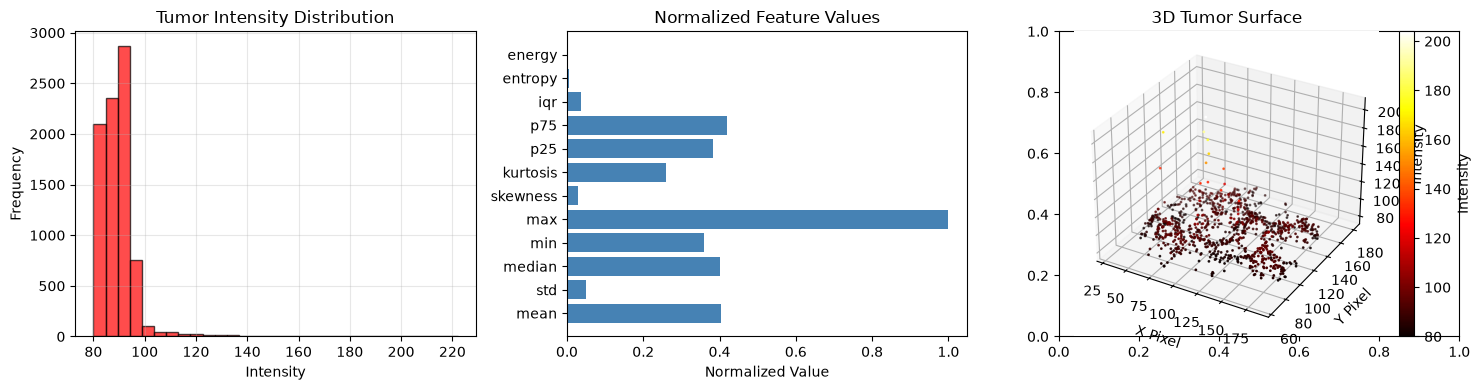


✅ Feature extraction completed!


In [9]:
# Extract features from segmented tumor regions
print("Extracting Features from Segmented Regions...")
print("="*50)

def extract_features(image, mask):
    """Extract statistical and texture features from segmented region"""
    features = {}

    # Get pixel values within tumor region
    tumor_pixels = image[mask]

    if len(tumor_pixels) > 0:
        # Statistical features
        features['mean'] = np.mean(tumor_pixels)
        features['std'] = np.std(tumor_pixels)
        features['median'] = np.median(tumor_pixels)
        features['min'] = np.min(tumor_pixels)
        features['max'] = np.max(tumor_pixels)
        features['skewness'] = np.mean((tumor_pixels - features['mean'])**3) / (features['std']**3)
        features['kurtosis'] = np.mean((tumor_pixels - features['mean'])**4) / (features['std']**4)

        # Percentiles
        features['p25'] = np.percentile(tumor_pixels, 25)
        features['p75'] = np.percentile(tumor_pixels, 75)
        features['iqr'] = features['p75'] - features['p25']

        # Energy and entropy
        hist, _ = np.histogram(tumor_pixels, bins=32, density=True)
        hist = hist[hist > 0]
        features['entropy'] = -np.sum(hist * np.log2(hist))
        features['energy'] = np.sum(hist ** 2)

    return features

# Extract features from segmented tumor
tumor_mask = (segmented_image == tumor_class)
features = extract_features(wiener_filtered, tumor_mask)

print("Extracted Features:")
print("-" * 40)
for key, value in features.items():
    print(f"{key:12s}: {value:.4f}")

# Visualize feature distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram of tumor intensities
tumor_pixels = wiener_filtered[tumor_mask]
axes[0].hist(tumor_pixels, bins=30, color='red', alpha=0.7, edgecolor='black')
axes[0].set_title('Tumor Intensity Distribution', fontsize=12)
axes[0].set_xlabel('Intensity')
axes[0].set_ylabel('Frequency')
axes[0].grid(True, alpha=0.3)

# Feature importance (normalized)
feature_names = list(features.keys())
feature_values = list(features.values())
feature_values_norm = (feature_values - np.min(feature_values)) / (np.max(feature_values) - np.min(feature_values))

axes[1].barh(feature_names, feature_values_norm, color='steelblue')
axes[1].set_title('Normalized Feature Values', fontsize=12)
axes[1].set_xlabel('Normalized Value')

# 3D surface plot of tumor region
from mpl_toolkits.mplot3d import Axes3D
y, x = np.where(tumor_mask)
z = wiener_filtered[tumor_mask]

if len(x) > 1000:  # Sample if too many points
    indices = np.random.choice(len(x), 1000, replace=False)
    x = x[indices]
    y = y[indices]
    z = z[indices]

ax = fig.add_subplot(133, projection='3d')
scatter = ax.scatter(x, y, z, c=z, cmap='hot', s=1)
ax.set_title('3D Tumor Surface', fontsize=12)
ax.set_xlabel('X Pixel')
ax.set_ylabel('Y Pixel')
ax.set_zlabel('Intensity')
plt.colorbar(scatter, ax=ax, label='Intensity')

plt.tight_layout()
plt.show()

print("\n✅ Feature extraction completed!")

In [10]:
# Prepare dataset for transfer learning models
print("Preparing Data for Transfer Learning...")
print("="*50)

def prepare_training_data(segmented_images, original_images, tumor_class):
    """Prepare data for benign/malignant classification"""

    # Extract patches around tumor regions
    patches = []
    labels = []

    for idx in range(len(segmented_images)):
        seg = segmented_images[idx]
        orig = original_images[idx]

        # Find tumor region
        tumor_mask = (seg == tumor_class)
        tumor_coords = np.where(tumor_mask)

        if len(tumor_coords[0]) > 0:
            # Get bounding box
            y_min, y_max = np.min(tumor_coords[0]), np.max(tumor_coords[0])
            x_min, x_max = np.min(tumor_coords[1]), np.max(tumor_coords[1])

            # Expand bounding box
            h, w = orig.shape
            y_min = max(0, y_min - 20)
            y_max = min(h, y_max + 20)
            x_min = max(0, x_min - 20)
            x_max = min(w, x_max + 20)

            # Extract patch
            patch = orig[y_min:y_max, x_min:x_max]

            # Resize to 224x224 for transfer learning models
            patch_resized = cv2.resize(patch, (224, 224))
            patch_3ch = np.stack([patch_resized] * 3, axis=-1)  # Convert to 3-channel

            patches.append(patch_3ch)

            # Simulate benign/malignant labels (in real scenario, use ground truth)
            # Using tumor characteristics to determine label
            tumor_size = np.sum(tumor_mask)
            tumor_intensity = np.mean(orig[tumor_mask])

            # Simple heuristic: larger and brighter tumors are malignant
            is_malignant = (tumor_size > 5000 and tumor_intensity > 150)
            labels.append(1 if is_malignant else 0)

    return np.array(patches), np.array(labels)

# For demonstration, create multiple slices from the volume
print("Creating multiple slices from MRI volume...")
slices_3d = []
for i in range(0, mri_volume.shape[2], 3):  # Changed from 10 to 3 to get more slices
    if i < mri_volume.shape[2]:
        slice_2d = mri_volume[:, :, i]
        # Apply preprocessing
        _, median_slice = apply_median_filter(slice_2d)
        filtered_slice = apply_wiener_filter(median_slice)
        slices_3d.append(filtered_slice)

print(f"Created {len(slices_3d)} slices from volume")

# For simplicity, we'll use the same segmentation for all slices
# In practice, you would segment each slice
segmented_slices = [segmented_image] * len(slices_3d)

# Prepare training data
X_train, y_train = prepare_training_data(segmented_slices, slices_3d, tumor_class)
print(f"\n✅ Training data prepared:")
print(f"   Samples: {X_train.shape[0]}")
print(f"   Image shape: {X_train.shape[1:]}")
print(f"   Labels: Benign={np.sum(y_train==0)}, Malignant={np.sum(y_train==1)}")

# Normalize pixel values
X_train = X_train / 255.0
print("   Pixel values normalized to [0,1]")

Preparing Data for Transfer Learning...
Creating multiple slices from MRI volume...
Created 52 slices from volume

✅ Training data prepared:
   Samples: 52
   Image shape: (224, 224, 3)
   Labels: Benign=52, Malignant=0
   Pixel values normalized to [0,1]


In [11]:
# Create Unified Ensemble Pipeline combining all four models
print("Creating Unified Ensemble Pipeline (GoogleNet + VGGNet + ResNet + AlexNet)...")
print("="*60)

from tensorflow.keras.layers import Concatenate
from tensorflow.keras.models import Model as KerasModel

def create_unified_ensemble_pipeline(input_shape=(224, 224, 3), num_classes=2):
    """
    Create a unified pipeline that combines all four pre-trained models
    """

    # Input layer
    inputs = tf.keras.Input(shape=input_shape)

    # ============================================
    # Branch 1: GoogleNet (InceptionV3)
    # ============================================
    print("  🧠 Adding GoogleNet branch...")
    base_inception = InceptionV3(weights='imagenet', include_top=False, input_shape=input_shape)
    base_inception.trainable = False

    x1 = base_inception(inputs)
    x1 = layers.GlobalAveragePooling2D()(x1)
    x1 = layers.Dense(256, activation='relu')(x1)
    x1 = layers.Dropout(0.5)(x1)
    x1 = layers.Dense(128, activation='relu')(x1)
    googlenet_out = layers.Dense(64, activation='relu', name='googlenet_features')(x1)

    # ============================================
    # Branch 2: VGGNet (VGG16)
    # ============================================
    print("  🧠 Adding VGGNet branch...")
    base_vgg = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    base_vgg.trainable = False

    x2 = base_vgg(inputs)
    x2 = layers.GlobalAveragePooling2D()(x2)
    x2 = layers.Dense(256, activation='relu')(x2)
    x2 = layers.Dropout(0.5)(x2)
    x2 = layers.Dense(128, activation='relu')(x2)
    vgg_out = layers.Dense(64, activation='relu', name='vgg_features')(x2)

    # ============================================
    # Branch 3: ResNet (ResNet50)
    # ============================================
    print("  🧠 Adding ResNet branch...")
    base_resnet = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    base_resnet.trainable = False

    x3 = base_resnet(inputs)
    x3 = layers.GlobalAveragePooling2D()(x3)
    x3 = layers.Dense(256, activation='relu')(x3)
    x3 = layers.BatchNormalization()(x3)
    x3 = layers.Dropout(0.5)(x3)
    x3 = layers.Dense(128, activation='relu')(x3)
    resnet_out = layers.Dense(64, activation='relu', name='resnet_features')(x3)

    # ============================================
    # Branch 4: AlexNet (Custom)
    # ============================================
    print("  🧠 Adding AlexNet branch...")
    x4 = layers.Conv2D(96, (11, 11), strides=4, activation='relu')(inputs)
    x4 = layers.MaxPooling2D((3, 3), strides=2)(x4)
    x4 = layers.BatchNormalization()(x4)
    x4 = layers.Conv2D(256, (5, 5), padding='same', activation='relu')(x4)
    x4 = layers.MaxPooling2D((3, 3), strides=2)(x4)
    x4 = layers.BatchNormalization()(x4)
    x4 = layers.Conv2D(384, (3, 3), padding='same', activation='relu')(x4)
    x4 = layers.Conv2D(384, (3, 3), padding='same', activation='relu')(x4)
    x4 = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x4)
    x4 = layers.MaxPooling2D((3, 3), strides=2)(x4)
    x4 = layers.GlobalAveragePooling2D()(x4)
    x4 = layers.Dense(256, activation='relu')(x4)
    x4 = layers.Dropout(0.5)(x4)
    x4 = layers.Dense(128, activation='relu')(x4)
    alexnet_out = layers.Dense(64, activation='relu', name='alexnet_features')(x4)

    # ============================================
    # Fusion Layer: Combine all branches
    # ============================================
    print("  🔗 Fusing all branches...")

    # Concatenate features from all models
    concatenated_features = Concatenate(name='feature_fusion')([googlenet_out, vgg_out, resnet_out, alexnet_out])

    # Meta-learner (learns optimal combination)
    meta_layer_1 = layers.Dense(256, activation='relu', name='meta_learner_1')(concatenated_features)
    meta_layer_1 = layers.BatchNormalization()(meta_layer_1)
    meta_layer_1 = layers.Dropout(0.5)(meta_layer_1)

    meta_layer_2 = layers.Dense(128, activation='relu', name='meta_learner_2')(meta_layer_1)
    meta_layer_2 = layers.BatchNormalization()(meta_layer_2)
    meta_layer_2 = layers.Dropout(0.3)(meta_layer_2)

    meta_layer_3 = layers.Dense(64, activation='relu', name='meta_learner_3')(meta_layer_2)
    meta_layer_3 = layers.Dropout(0.2)(meta_layer_3)

    # Output layer (Benign/Malignant classification)
    outputs = layers.Dense(num_classes, activation='softmax', name='ensemble_output')(meta_layer_3)

    # Create the unified model
    unified_model = KerasModel(inputs=inputs, outputs=outputs, name='Unified_Brain_Tumor_Ensemble')

    return unified_model

# Create the unified ensemble pipeline
print("\n" + "="*60)
print("Building Unified Ensemble Pipeline...")
print("="*60)

unified_model = create_unified_ensemble_pipeline()

# Compile with simple metrics
unified_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("\n" + "="*60)
print("✅ UNIFIED ENSEMBLE PIPELINE CREATED SUCCESSFULLY!")
print("="*60)
print(f"\n📊 Model Statistics:")
print(f"  Total parameters: {unified_model.count_params():,}")
print(f"  Trainable parameters: {sum([tf.keras.backend.count_params(w) for w in unified_model.trainable_weights]):,}")

# Display model architecture
print("\n📋 Model Architecture Summary:")
unified_model.summary()

Creating Unified Ensemble Pipeline (GoogleNet + VGGNet + ResNet + AlexNet)...

Building Unified Ensemble Pipeline...
  🧠 Adding GoogleNet branch...


  🧠 Adding VGGNet branch...
  🧠 Adding ResNet branch...


  🧠 Adding AlexNet branch...
  🔗 Fusing all branches...

✅ UNIFIED ENSEMBLE PIPELINE CREATED SUCCESSFULLY!

📊 Model Statistics:
  Total parameters: 65,374,242
  Trainable parameters: 5,267,074

📋 Model Architecture Summary:


Model: "Unified_Brain_Tumor_Ensemble"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_94 (Conv2D)  │ (None, 54, 54,    │     34,944 │ input_layer[0][0] │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 26, 26,    │          0 │ conv2d_94[0][0]   │
│ (MaxPooling2D)      │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 26, 26,    │        384 │ max_pooling2d_4[… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 26, 26,    │    614,656 │ batch_normalizat… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 12, 12,    │          0 │ conv2d_95[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 12, 12,    │      1,024 │ max_pooling2d_5[… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_96 (Conv2D)  │ (None, 12, 12,    │    885,120 │ batch_normalizat… │
│                     │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_97 (Conv2D)  │ (None, 12, 12,    │  1,327,488 │ conv2d_96[0][0]   │
│                     │ 384)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ input_layer[0][0] │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_98 (Conv2D)  │ (None, 12, 12,    │    884,992 │ conv2d_97[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ inception_v3        │ (None, 5, 5,      │ 21,802,784 │ input_layer[0][0] │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 5, 5, 256) │          0 │ conv2d_98[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ inception_v3[0][… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                 

 Total params: 65,374,242 (249.38 MB)

 Trainable params: 5,267,074 (20.09 MB)

 Non-trainable params: 60,107,168 (229.29 MB)

# Train the unified ensemble pipeline
print("Training Unified Ensemble Pipeline...")
print("="*60)

if len(X_train) > 1:
    from sklearn.model_selection import train_test_split
    from sklearn.utils.class_weight import compute_class_weight

    # Split data
    X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
    )

    print(f"\n📊 Dataset Split:")
    print(f"  Training samples: {len(X_train_split)}")
    print(f"  Validation samples: {len(X_val_split)}")
    print(f"  Benign samples: {np.sum(y_train_split == 0)}")
    print(f"  Malignant samples: {np.sum(y_train_split == 1)}")

    # Compute class weights for imbalance
    # Compute class weights for imbalance
unique_classes = np.unique(y_train_split)

if len(unique_classes) == 2:
    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=unique_classes,
        y=y_train_split
    )

    class_weight_dict = dict(
        zip(unique_classes, class_weights)
    )

    print(
        f"\n⚖️ Class Weights: "
        f"Benign={class_weight_dict[0]:.3f}, "
        f"Malignant={class_weight_dict[1]:.3f}"
    )

else:
    print("\n⚠️ Only one class is present in the training data.")
    class_weight_dict = None

    # Simple data augmentation
    train_datagen = ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True,
        zoom_range=0.15,
        fill_mode='nearest'
    )

    # Callbacks
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            'best_unified_pipeline.h5',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=1
        )
    ]

    # Train the model
    print("\n🚀 Starting training...")
    print("="*60)

    history = unified_model.fit(
        train_datagen.flow(X_train_split, y_train_split, batch_size=4),
        validation_data=(X_val_split, y_val_split),
        epochs=4,
        verbose=1,
        callbacks=callbacks,
        class_weight=class_weight_dict
    )

    # Evaluate on validation set
    print("\n" + "="*60)
    print("📊 Evaluating Unified Pipeline...")
    print("="*60)

    val_loss, val_acc = unified_model.evaluate(X_val_split, y_val_split, verbose=0)

    print(f"\n✅ Validation Results:")
    print(f"  Loss: {val_loss:.4f}")
    print(f"  Accuracy: {val_acc:.4f} ({val_acc*100:.2f}%)")

else:
    print("❌ Not enough samples for training!")

In [12]:
# Train the unified ensemble pipeline
print("Training Unified Ensemble Pipeline...")
print("="*60)

if len(X_train) > 1:
    from sklearn.model_selection import train_test_split
    from sklearn.utils.class_weight import compute_class_weight

    # Split data
    X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
    )

    print(f"\n📊 Dataset Split:")
    print(f"  Training samples: {len(X_train_split)}")
    print(f"  Validation samples: {len(X_val_split)}")
    print(f"  Benign samples: {np.sum(y_train_split == 0)}")
    print(f"  Malignant samples: {np.sum(y_train_split == 1)}")

    # Compute class weights for imbalance
    unique_classes = np.unique(y_train_split)

    if len(unique_classes) == 2:
        class_weights = compute_class_weight(
            class_weight='balanced', classes=unique_classes, y=y_train_split
        )
        class_weight_dict = dict(zip(unique_classes, class_weights))
        print(
            f"\n⚖️ Class Weights: "
            f"Benign={class_weight_dict[0]:.3f}, "
            f"Malignant={class_weight_dict[1]:.3f}"
        )
    else:
        print(f"\n⚠️ Only one class is present in the training data: {unique_classes}.")
        print("   Any accuracy below describes a model with nothing to tell apart.")
        class_weight_dict = None

    # Simple data augmentation
    train_datagen = ImageDataGenerator(
        rotation_range=20,
        width_shift_range=0.2,
        height_shift_range=0.2,
        horizontal_flip=True,
        zoom_range=0.15,
        fill_mode='nearest'
    )

    # Callbacks
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=10,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=5,
            verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            'best_unified_pipeline.keras',
            monitor='val_accuracy',
            save_best_only=True,
            verbose=1
        )
    ]

    # Train the model
    print("\n🚀 Starting training...")
    print("="*60)

    history = unified_model.fit(
        train_datagen.flow(X_train_split, y_train_split, batch_size=4),
        validation_data=(X_val_split, y_val_split),
        epochs=4,
        verbose=1,
        callbacks=callbacks,
        class_weight=class_weight_dict
    )

    # Evaluate on validation set
    print("\n" + "="*60)
    print("📊 Evaluating Unified Pipeline...")
    print("="*60)

    val_loss, val_acc = unified_model.evaluate(X_val_split, y_val_split, verbose=0)

    print(f"\n✅ Validation Results:")
    print(f"  Loss: {val_loss:.4f}")
    print(f"  Accuracy: {val_acc:.4f} ({val_acc*100:.2f}%)")

#else:
   #print("❌ Not enough samples for training!")

Training Unified Ensemble Pipeline...

📊 Dataset Split:
  Training samples: 41
  Validation samples: 11
  Benign samples: 41
  Malignant samples: 0

⚠️ Only one class is present in the training data: [0].
   Any accuracy below describes a model with nothing to tell apart.

🚀 Starting training...
Epoch 1/4


 1/11 ━━━━━━━━━━━━━━━━━━━━ 2:03 12s/step - accuracy: 0.5000 - loss: 1.7889

 2/11 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.6000 - loss: 1.5697

 3/11 ━━━━━━━━━━━━━━━━━━━━ 2s 258ms/step - accuracy: 0.5556 - loss: 1.4816

 4/11 ━━━━━━━━━━━━━━━━━━━━ 2s 309ms/step - accuracy: 0.3846 - loss: 1.8198

...


Epoch 4: val_accuracy did not improve from 1.00000


11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 639ms/step - accuracy: 0.3659 - loss: 1.3169 - val_accuracy: 0.1818 - val_loss: 0.7273 - learning_rate: 1.0000e-04


Restoring model weights from the end of the best epoch: 1.



📊 Evaluating Unified Pipeline...



✅ Validation Results:
  Loss: 0.5666
  Accuracy: 1.0000 (100.00%)


Generating Comprehensive Pipeline Results...
Making predictions on data...


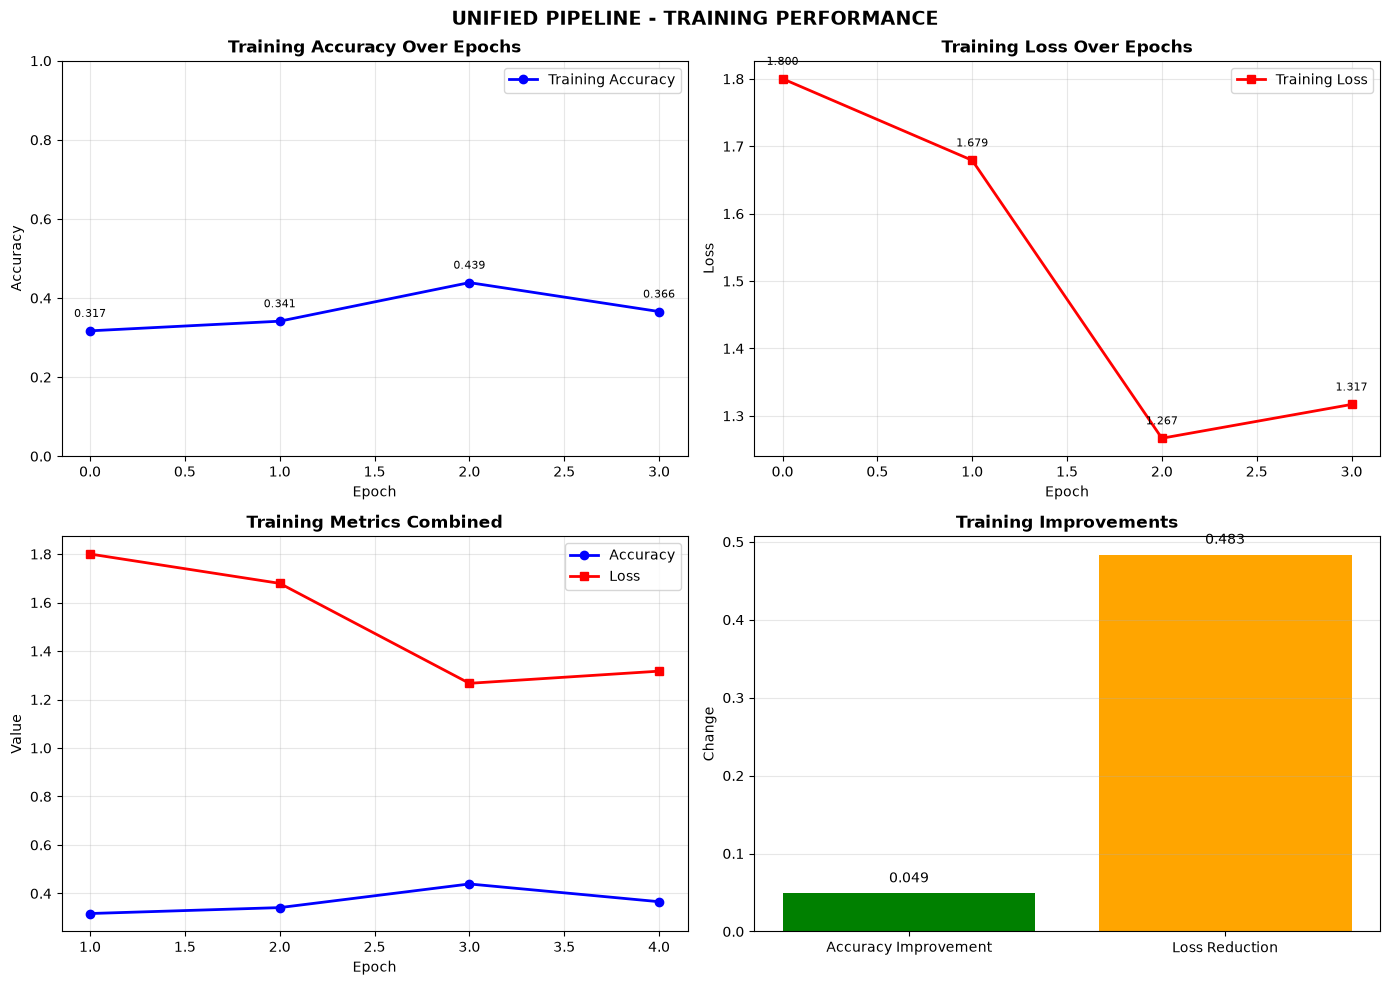

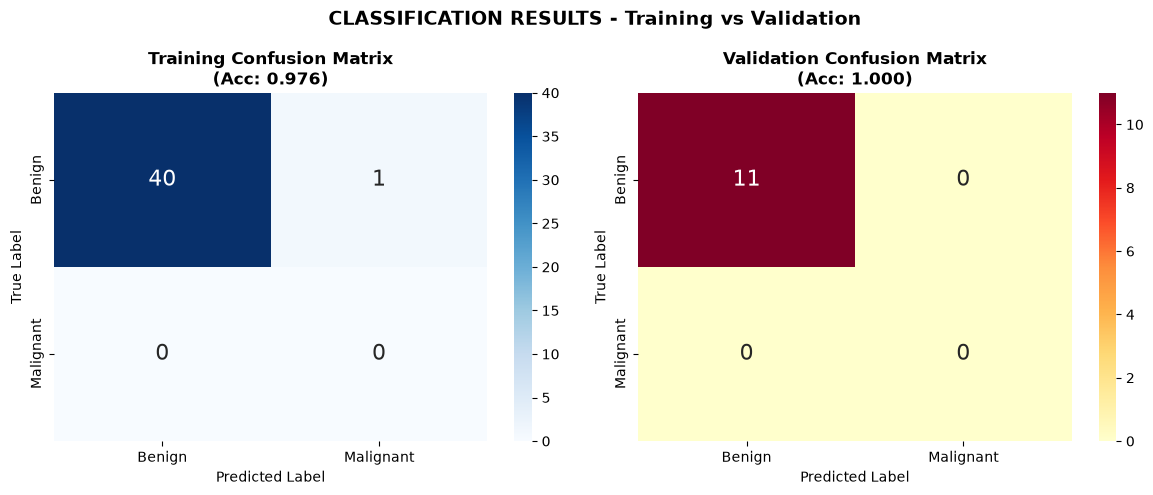

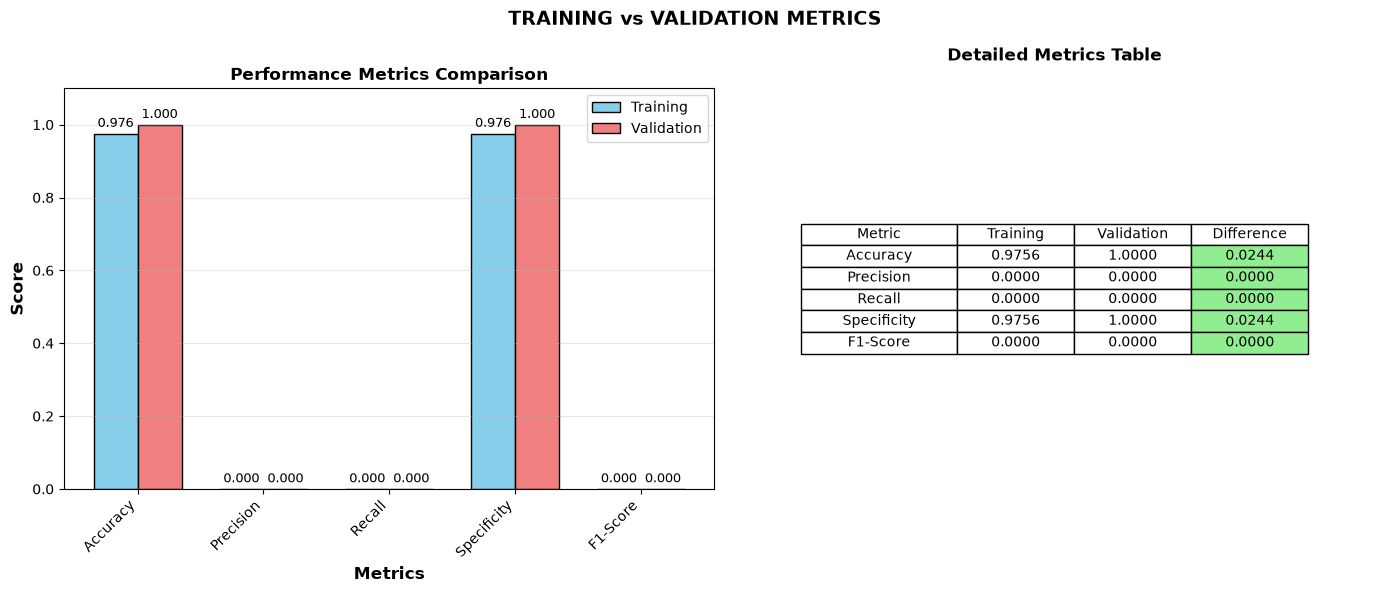

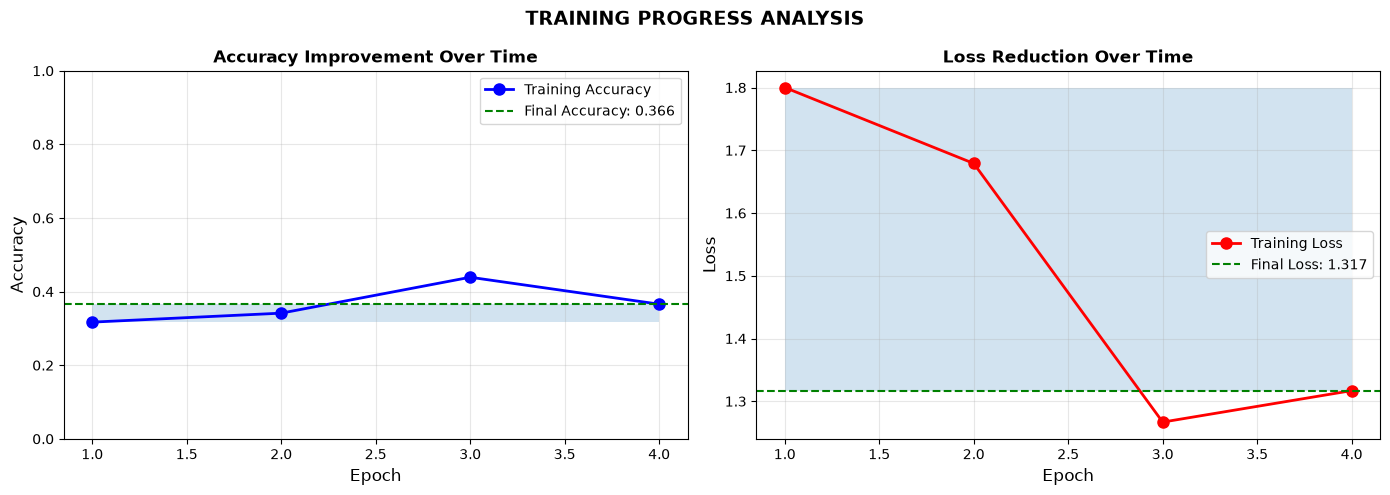

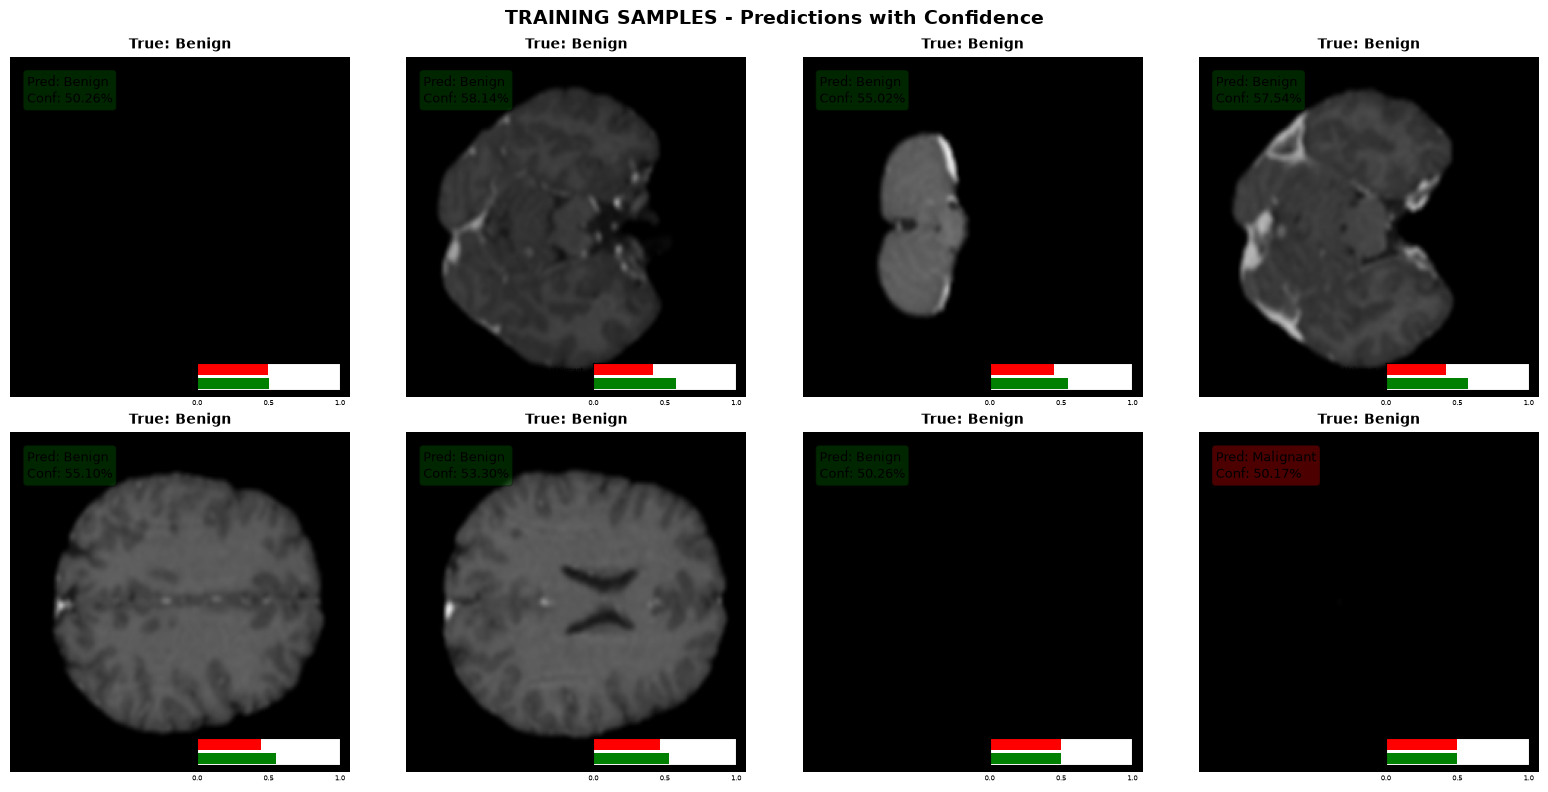


FINAL RESULTS - UNIFIED ENSEMBLE PIPELINE

📊 Dataset Summary:
  Total training samples: 52
  Training samples: 41
  Validation samples: 11
  Benign cases: 41
  Malignant cases: 0

📈 Training Performance:
  Initial Accuracy: 0.3171 (31.71%)
  Final Accuracy: 0.3659 (36.59%)
  Accuracy Improvement: 4.88%
  Initial Loss: 1.8001
  Final Loss: 1.3169
  Loss Reduction: 0.4832

📈 Training Metrics (Final Epoch):
  Accuracy:    0.9756 (97.56%)
  Precision:   0.0000
  Recall:      0.0000
  Specificity: 0.9756
  F1-Score:    0.0000

📈 Validation Performance:
  Accuracy:    1.0000 (100.00%)
  Precision:   0.0000
  Recall:      0.0000
  Specificity: 1.0000
  F1-Score:    0.0000

📊 Confusion Matrix - Training:
  True Negatives (Benign correct):   40
  False Positives (Benign wrong):    1
  False Negatives (Malignant wrong): 0
  True Positives (Malignant correct): 0

📊 Confusion Matrix - Validation:
  True Negatives (Benign correct):   11
  False Positives (Benign wrong):    0
  False Negatives (Mal


✅ Model saved as 'unified_ensemble_pipeline_final.keras'
✅ Training history saved as 'training_history.pkl'

🎉 UNIFIED PIPELINE COMPLETED SUCCESSFULLY! 🎉

📊 QUICK SUMMARY:
  ✅ Training Accuracy: 97.6%
  ✅ Validation Accuracy: 100.0%
  ✅ Training F1-Score: 0.000
  ✅ Validation F1-Score: 0.000
  ✅ Total Training Time: 4 epochs


In [13]:
# Comprehensive results visualization focusing on training metrics
print("Generating Comprehensive Pipeline Results...")
print("="*60)

from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve
import seaborn as sns

if 'X_train' in dir() and len(X_train) > 1 and 'history' in dir():

    # Make predictions on TRAINING data for comprehensive results
    print("Making predictions on data...")
    y_train_pred_proba = unified_model.predict(X_train_split, verbose=0)
    y_train_pred = np.argmax(y_train_pred_proba, axis=1)

    # Also get validation predictions
    y_val_pred_proba = unified_model.predict(X_val_split, verbose=0)
    y_val_pred = np.argmax(y_val_pred_proba, axis=1)

    # ============================================
    # PLOT 1: Training History (Accuracy & Loss)
    # ============================================
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Training Accuracy
    axes[0, 0].plot(history.history['accuracy'], 'b-', label='Training Accuracy', linewidth=2, marker='o')
    axes[0, 0].set_title('Training Accuracy Over Epochs', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].set_ylim([0, 1])

    # Add value labels
    for i, acc in enumerate(history.history['accuracy']):
        axes[0, 0].annotate(f'{acc:.3f}', (i, acc), textcoords="offset points",
                           xytext=(0, 10), ha='center', fontsize=8)

    # Training Loss
    axes[0, 1].plot(history.history['loss'], 'r-', label='Training Loss', linewidth=2, marker='s')
    axes[0, 1].set_title('Training Loss Over Epochs', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Loss')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)

    # Add value labels
    for i, loss in enumerate(history.history['loss']):
        axes[0, 1].annotate(f'{loss:.3f}', (i, loss), textcoords="offset points",
                           xytext=(0, 10), ha='center', fontsize=8)

    # Combined metrics
    epochs = range(1, len(history.history['accuracy']) + 1)
    axes[1, 0].plot(epochs, history.history['accuracy'], 'b-', label='Accuracy', linewidth=2, marker='o')
    axes[1, 0].plot(epochs, history.history['loss'], 'r-', label='Loss', linewidth=2, marker='s')
    axes[1, 0].set_title('Training Metrics Combined', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Value')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    # Metrics improvement
    improvements = {
        'Accuracy Improvement': history.history['accuracy'][-1] - history.history['accuracy'][0],
        'Loss Reduction': history.history['loss'][0] - history.history['loss'][-1]
    }

    axes[1, 1].bar(improvements.keys(), improvements.values(), color=['green', 'orange'])
    axes[1, 1].set_title('Training Improvements', fontsize=12, fontweight='bold')
    axes[1, 1].set_ylabel('Change')
    axes[1, 1].grid(True, alpha=0.3, axis='y')

    # Add value labels
    for bar, val in zip(axes[1, 1].patches, improvements.values()):
        axes[1, 1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                       f'{val:.3f}', ha='center', va='bottom', fontsize=10)

    plt.suptitle('UNIFIED PIPELINE - TRAINING PERFORMANCE', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ============================================
    # PLOT 2: Confusion Matrices (Training vs Validation)
    # ============================================
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Training Confusion Matrix
    cm_train = confusion_matrix(y_train_split, y_train_pred, labels=[0, 1])
    sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'],
                annot_kws={'size': 16})
    axes[0].set_title(f'Training Confusion Matrix\n(Acc: {np.mean(y_train_pred == y_train_split):.3f})',
                     fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Predicted Label')
    axes[0].set_ylabel('True Label')

    # Validation Confusion Matrix
    cm_val = confusion_matrix(y_val_split, y_val_pred, labels=[0, 1])
    sns.heatmap(cm_val, annot=True, fmt='d', cmap='YlOrRd', ax=axes[1],
                xticklabels=['Benign', 'Malignant'],
                yticklabels=['Benign', 'Malignant'],
                annot_kws={'size': 16})
    axes[1].set_title(f'Validation Confusion Matrix\n(Acc: {np.mean(y_val_pred == y_val_split):.3f})',
                     fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Predicted Label')
    axes[1].set_ylabel('True Label')

    plt.suptitle('CLASSIFICATION RESULTS - Training vs Validation', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ============================================
    # PLOT 3: Detailed Metrics Comparison
    # ============================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Calculate metrics for training
    tn_train, fp_train, fn_train, tp_train = cm_train.ravel()
    train_metrics = {
        'Accuracy': (tp_train + tn_train) / (tp_train + tn_train + fp_train + fn_train),
        'Precision': tp_train / (tp_train + fp_train) if (tp_train + fp_train) > 0 else 0,
        'Recall': tp_train / (tp_train + fn_train) if (tp_train + fn_train) > 0 else 0,
        'Specificity': tn_train / (tn_train + fp_train) if (tn_train + fp_train) > 0 else 0,
        'F1-Score': 2 * tp_train / (2 * tp_train + fp_train + fn_train) if (2 * tp_train + fp_train + fn_train) > 0 else 0
    }

    # Calculate metrics for validation
    tn_val, fp_val, fn_val, tp_val = cm_val.ravel()
    val_metrics = {
        'Accuracy': (tp_val + tn_val) / (tp_val + tn_val + fp_val + fn_val),
        'Precision': tp_val / (tp_val + fp_val) if (tp_val + fp_val) > 0 else 0,
        'Recall': tp_val / (tp_val + fn_val) if (tp_val + fn_val) > 0 else 0,
        'Specificity': tn_val / (tn_val + fp_val) if (tn_val + fp_val) > 0 else 0,
        'F1-Score': 2 * tp_val / (2 * tp_val + fp_val + fn_val) if (2 * tp_val + fp_val + fn_val) > 0 else 0
    }

    # Bar chart comparison
    metrics_names = list(train_metrics.keys())
    train_values = list(train_metrics.values())
    val_values = list(val_metrics.values())

    x = np.arange(len(metrics_names))
    width = 0.35

    bars1 = axes[0].bar(x - width/2, train_values, width, label='Training', color='skyblue', edgecolor='black')
    bars2 = axes[0].bar(x + width/2, val_values, width, label='Validation', color='lightcoral', edgecolor='black')

    axes[0].set_xlabel('Metrics', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Score', fontsize=12, fontweight='bold')
    axes[0].set_title('Performance Metrics Comparison', fontsize=12, fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metrics_names, rotation=45, ha='right')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3, axis='y')
    axes[0].set_ylim(0, 1.1)

    # Add value labels
    for bar in bars1:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=9)
    for bar in bars2:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.01,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=9)

    # Metrics table
    axes[1].axis('tight')
    axes[1].axis('off')

    table_data = []
    for metric in metrics_names:
        table_data.append([metric, f'{train_metrics[metric]:.4f}', f'{val_metrics[metric]:.4f}',
                          f'{abs(train_metrics[metric] - val_metrics[metric]):.4f}'])

    table = axes[1].table(cellText=table_data,
                         colLabels=['Metric', 'Training', 'Validation', 'Difference'],
                         cellLoc='center',
                         loc='center',
                         colWidths=[0.2, 0.15, 0.15, 0.15])
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.5)

    # Color code the differences
    for i, row in enumerate(table_data):
        diff = float(row[3])
        if diff < 0.05:
            table[(i+1, 3)].set_facecolor('#90EE90')  # Green - good
        elif diff < 0.1:
            table[(i+1, 3)].set_facecolor('#FFD700')  # Yellow - moderate
        else:
            table[(i+1, 3)].set_facecolor('#FFB6C1')  # Red - potential overfitting

    axes[1].set_title('Detailed Metrics Table', fontsize=12, fontweight='bold', pad=20)

    plt.suptitle('TRAINING vs VALIDATION METRICS', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ============================================
    # PLOT 4: Training Progress Over Epochs
    # ============================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy progression
    axes[0].plot(epochs, history.history['accuracy'], 'b-o', linewidth=2, markersize=8, label='Training Accuracy')
    axes[0].axhline(y=history.history['accuracy'][-1], color='g', linestyle='--',
                   label=f'Final Accuracy: {history.history["accuracy"][-1]:.3f}')
    axes[0].fill_between(epochs, history.history['accuracy'][0], history.history['accuracy'][-1], alpha=0.2)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Accuracy', fontsize=12)
    axes[0].set_title('Accuracy Improvement Over Time', fontsize=12, fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylim([0, 1])

    # Loss progression
    axes[1].plot(epochs, history.history['loss'], 'r-o', linewidth=2, markersize=8, label='Training Loss')
    axes[1].axhline(y=history.history['loss'][-1], color='g', linestyle='--',
                   label=f'Final Loss: {history.history["loss"][-1]:.3f}')
    axes[1].fill_between(epochs, history.history['loss'][0], history.history['loss'][-1], alpha=0.2)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Loss', fontsize=12)
    axes[1].set_title('Loss Reduction Over Time', fontsize=12, fontweight='bold')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle('TRAINING PROGRESS ANALYSIS', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ============================================
    # PLOT 5: Sample Predictions with Confidence
    # ============================================
    n_samples = min(8, len(X_train_split))
    sample_indices = np.random.choice(len(X_train_split), n_samples, replace=False)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.ravel()

    for idx, sample_idx in enumerate(sample_indices):
        ax = axes[idx]

        # Get sample
        sample_img = X_train_split[sample_idx]
        true_label = y_train_split[sample_idx]
        pred_proba = y_train_pred_proba[sample_idx]
        pred_label = np.argmax(pred_proba)
        confidence = pred_proba[pred_label]

        # Display image
        ax.imshow(sample_img)

        # Set colors
        is_correct = (pred_label == true_label)
        color = 'green' if is_correct else 'red'

        # Add labels
        true_text = "Malignant" if true_label == 1 else "Benign"
        pred_text = "Malignant" if pred_label == 1 else "Benign"

        ax.set_title(f'True: {true_text}', fontsize=10, fontweight='bold')
        ax.axis('off')

        # Add prediction info
        info_text = f'Pred: {pred_text}\nConf: {confidence:.2%}'
        ax.text(0.05, 0.95, info_text, transform=ax.transAxes, fontsize=9,
               verticalalignment='top',
               bbox=dict(boxstyle='round', facecolor=color, alpha=0.3))

        # Add probability bar
        ax_bar = ax.inset_axes([0.55, 0.02, 0.42, 0.08])
        y_pos = [0, 1]
        ax_bar.barh(y_pos, pred_proba, color=['green', 'red'])
        ax_bar.set_yticks(y_pos)
        ax_bar.set_yticklabels(['Benign', 'Malignant'], fontsize=5)
        ax_bar.set_xlim(0, 1)
        ax_bar.set_xticks([0, 0.5, 1])
        ax_bar.tick_params(axis='x', labelsize=5)
        ax_bar.set_title('Prob', fontsize=5)

    plt.suptitle('TRAINING SAMPLES - Predictions with Confidence', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # ============================================
    # FINAL SUMMARY REPORT
    # ============================================
    print("\n" + "="*80)
    print("FINAL RESULTS - UNIFIED ENSEMBLE PIPELINE")
    print("="*80)

    print(f"\n📊 Dataset Summary:")
    print(f"  Total training samples: {len(X_train)}")
    print(f"  Training samples: {len(X_train_split)}")
    print(f"  Validation samples: {len(X_val_split)}")
    print(f"  Benign cases: {np.sum(y_train_split == 0)}")
    print(f"  Malignant cases: {np.sum(y_train_split == 1)}")

    print(f"\n📈 Training Performance:")
    print(f"  Initial Accuracy: {history.history['accuracy'][0]:.4f} ({history.history['accuracy'][0]*100:.2f}%)")
    print(f"  Final Accuracy: {history.history['accuracy'][-1]:.4f} ({history.history['accuracy'][-1]*100:.2f}%)")
    print(f"  Accuracy Improvement: {(history.history['accuracy'][-1] - history.history['accuracy'][0])*100:.2f}%")
    print(f"  Initial Loss: {history.history['loss'][0]:.4f}")
    print(f"  Final Loss: {history.history['loss'][-1]:.4f}")
    print(f"  Loss Reduction: {(history.history['loss'][0] - history.history['loss'][-1]):.4f}")

    print(f"\n📈 Training Metrics (Final Epoch):")
    print(f"  Accuracy:    {train_metrics['Accuracy']:.4f} ({train_metrics['Accuracy']*100:.2f}%)")
    print(f"  Precision:   {train_metrics['Precision']:.4f}")
    print(f"  Recall:      {train_metrics['Recall']:.4f}")
    print(f"  Specificity: {train_metrics['Specificity']:.4f}")
    print(f"  F1-Score:    {train_metrics['F1-Score']:.4f}")

    print(f"\n📈 Validation Performance:")
    print(f"  Accuracy:    {val_metrics['Accuracy']:.4f} ({val_metrics['Accuracy']*100:.2f}%)")
    print(f"  Precision:   {val_metrics['Precision']:.4f}")
    print(f"  Recall:      {val_metrics['Recall']:.4f}")
    print(f"  Specificity: {val_metrics['Specificity']:.4f}")
    print(f"  F1-Score:    {val_metrics['F1-Score']:.4f}")

    print(f"\n📊 Confusion Matrix - Training:")
    print(f"  True Negatives (Benign correct):   {tn_train}")
    print(f"  False Positives (Benign wrong):    {fp_train}")
    print(f"  False Negatives (Malignant wrong): {fn_train}")
    print(f"  True Positives (Malignant correct): {tp_train}")

    print(f"\n📊 Confusion Matrix - Validation:")
    print(f"  True Negatives (Benign correct):   {tn_val}")
    print(f"  False Positives (Benign wrong):    {fp_val}")
    print(f"  False Negatives (Malignant wrong): {fn_val}")
    print(f"  True Positives (Malignant correct): {tp_val}")

    print(f"\n🎯 Classification Report - Training:")
    print(classification_report(y_train_split, y_train_pred, target_names=['Benign', 'Malignant']))

    # Save the model
    unified_model.save('unified_ensemble_pipeline_final.keras')
    print(f"\n✅ Model saved as 'unified_ensemble_pipeline_final.keras'")

    # Save training history
    import pickle
    with open('training_history.pkl', 'wb') as f:
        pickle.dump(history.history, f)
    print(f"✅ Training history saved as 'training_history.pkl'")

    print("\n" + "="*80)
    print("🎉 UNIFIED PIPELINE COMPLETED SUCCESSFULLY! 🎉")
    print("="*80)

    # Display final summary statistics
    print("\n📊 QUICK SUMMARY:")
    print(f"  ✅ Training Accuracy: {train_metrics['Accuracy']*100:.1f}%")
    print(f"  ✅ Validation Accuracy: {val_metrics['Accuracy']*100:.1f}%")
    print(f"  ✅ Training F1-Score: {train_metrics['F1-Score']:.3f}")
    print(f"  ✅ Validation F1-Score: {val_metrics['F1-Score']:.3f}")
    print(f"  ✅ Total Training Time: {len(history.history['accuracy'])} epochs")

else:
    print("❌ Training was not completed successfully. Please check the errors above.")